In [1]:
import geopandas as gpd
from utils import *
import matplotlib.pyplot as plt
from PIL import ImageChops

In [2]:
roads = gpd.read_file("shp/gis_osm_roads_free_1.shp")
land = gpd.read_file("shp/gis_osm_landuse_a_free_1.shp")

print(roads["fclass"].unique())
print(land["fclass"].unique())

roads = roads[roads["fclass"].isin([
    "motorway",
    "primary",
    "secondary",
    "tertiary",
    "residential",
    # "cycleway"
])]

land = land[land["fclass"].isin([
    "scrub",
    "farmland",
    "grass",
    "forest",
    "heath",
    "park",
    "meadow",
    "nature_reserve",
    "farmyard",
])]


<StringArray>
[       'primary',    'residential',          'trunk',        'footway',
        'service',   'unclassified',       'tertiary',   'primary_link',
      'secondary',  'motorway_link',       'cycleway',       'motorway',
  'tertiary_link',      'bridleway',     'trunk_link',     'pedestrian',
  'living_street',          'steps',          'track',           'path',
   'track_grade1',   'track_grade2',   'track_grade5', 'secondary_link',
   'track_grade3',   'track_grade4',         'busway',        'unknown']
Length: 28, dtype: str
<StringArray>
[             'park',    'nature_reserve',            'forest',
        'industrial',            'retail', 'recreation_ground',
            'meadow',       'residential',          'cemetery',
             'grass',             'scrub',        'allotments',
          'military',            'quarry',        'commercial',
             'heath',          'farmland',          'farmyard',
           'orchard']
Length: 19, dtype: str


In [3]:
# Clip to a 40-mile radius around the specified coordinates
bbox_lon, bbox_lat = -0.127683, 51.507368
# Approximately 40 miles = 65 km, in degrees ≈ 0.6 degrees
delta = 0.40
bbox = (bbox_lon - delta, bbox_lat - delta, bbox_lon + delta, bbox_lat + delta)
roads = clip_to_bbox(roads, bbox)
land = clip_to_bbox(land, bbox)

counter = 0
z = 15

width_map={
        "motorway": 15.0,
        "primary":  15.0,
        "secondary": 15.0,
        "tertiary": 15.0,
        "residential": 15.0,
        # "cycleway": 20,
    }

total_bounds = roads.total_bounds
min_bound = tile_from_lonlat(total_bounds[0], total_bounds[1], z)
max_bound = tile_from_lonlat(total_bounds[2], total_bounds[3], z)

print(total_bounds)
print(min_bound)
print(max_bound)

for x in range(min_bound[0], max_bound[0] + 1):
    
    for y in range(max_bound[1], min_bound[1] + 1):
        if counter % 100 == 0:
            print(f"Rendering tile {counter}: x={x}, y={y}, z={z}")
        # if counter == 100:
        #     break
        counter += 1
        
        tile_roads = render_roads_to_tile(
            roads,
            x=x,
            y=y,
            z=z,
            tile_size=120,
            width_map=width_map,
            )

        tile_land = render_roads_to_tile(
            land,
            x=x,
            y=y,
            z=z,
            tile_size=120           
        )

        tile_check = checkered_pattern()

        tile_check = tile_check.convert("1")
        tile_roads = tile_roads.convert("1")
        tile_land = tile_land.convert("1")

        tile_land = ImageChops.multiply(tile_land, tile_check)

        tile = ImageChops.add(tile_roads, tile_land)

        tile.save(f"{get_subdirectory(y,z)}{x}.bmp")

    # if counter == 100:
    #     break

[-0.5153219 51.2832276  0.272317  51.6975114]
(16337, 10928)
(16408, 10868)
Rendering tile 0: x=16337, y=10868, z=15
Rendering tile 100: x=16338, y=10907, z=15
Rendering tile 200: x=16340, y=10885, z=15
Rendering tile 300: x=16341, y=10924, z=15
Rendering tile 400: x=16343, y=10902, z=15
Rendering tile 500: x=16345, y=10880, z=15
Rendering tile 600: x=16346, y=10919, z=15
Rendering tile 700: x=16348, y=10897, z=15
Rendering tile 800: x=16350, y=10875, z=15
Rendering tile 900: x=16351, y=10914, z=15
Rendering tile 1000: x=16353, y=10892, z=15
Rendering tile 1100: x=16355, y=10870, z=15
Rendering tile 1200: x=16356, y=10909, z=15
Rendering tile 1300: x=16358, y=10887, z=15
Rendering tile 1400: x=16359, y=10926, z=15
Rendering tile 1500: x=16361, y=10904, z=15
Rendering tile 1600: x=16363, y=10882, z=15
Rendering tile 1700: x=16364, y=10921, z=15
Rendering tile 1800: x=16366, y=10899, z=15
Rendering tile 1900: x=16368, y=10877, z=15
Rendering tile 2000: x=16369, y=10916, z=15
Rendering ti

<Axes: >

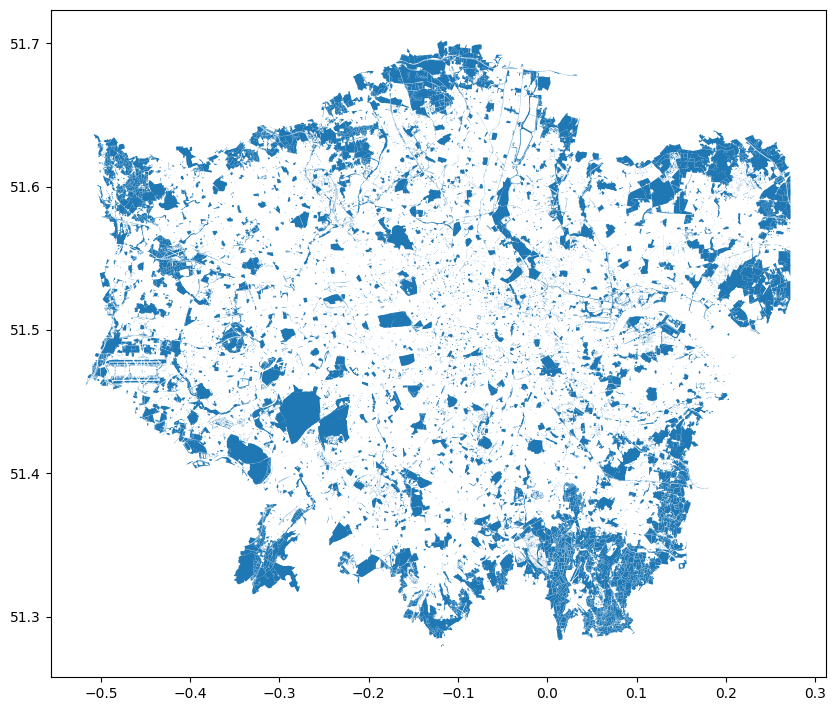

In [4]:
land.plot(figsize=(10,10))